# 08: Subdivide tissue in larger hexes

In [4]:
import spatialdata as sd
import spatialdata_plot
from pathlib import Path
import matplotlib.pyplot as plt
from spatialdata.models import Labels2DModel
import xarray as xr
import numpy as np
from affine import Affine
import seaborn as sns
from rasterio.features import rasterize
from tqdm import tqdm
from math import ceil
from shapely.geometry import Polygon
from geopandas import GeoDataFrame
from concurrent.futures import ProcessPoolExecutor
from tqdm import tqdm
from math import ceil, sqrt



In [2]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")

In [3]:
sdata_sample1 = sd.read_zarr(data_dir / "xenium_sample1_subset_baked.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


In [5]:
sdata_sample1

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_subset_baked.zarr
├── Images
│     ├── 'hne': DataTree[cyx] (3, 42947, 38096), (3, 21473, 19048), (3, 10736, 9524), (3, 5368, 4762)
│     ├── 'hne_baked': DataTree[cyx] (3, 55732, 49529), (3, 27865, 24764), (3, 13932, 12382), (3, 6966, 6191)
│     ├── 'morphology_focus': DataTree[cyx] (1, 53833, 48441), (1, 26916, 24220), (1, 13458, 12110), (1, 6729, 6055), (1, 3364, 3027)
│     └── 'morphology_mip': DataTree[cyx] (1, 53833, 48441), (1, 26916, 24220), (1, 13458, 12110), (1, 6729, 6055), (1, 3364, 3027)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (53833, 48441), (26916, 24220), (13458, 12110), (6729, 6055), (3364, 3027)
│     ├── 'cell_labels_subset': DataTree[yx] (53833, 48441), (26916, 24220), (13458, 12110), (6729, 6055), (3364, 3027)
│     └── 'nucleus_labels': DataTree[yx] (53833, 48441), (26916, 24220), (13458, 12110), (6729, 6055), (3364, 3027)
├── Po

INFO     Rasterizing image for faster rendering.                                                                   


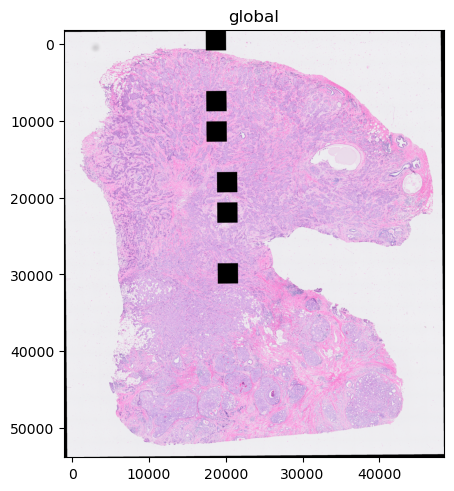

In [6]:
(
    sdata_sample1.pl.render_images("hne_baked").pl.show()
)

In [7]:
_, y_max, x_max = sdata_sample1["morphology_focus"]["scale0"].image.shape

sdata_crop = (
    sdata_sample1
    .query.bounding_box(
        axes=["x", "y"],
        min_coordinate=[0, 0],
        max_coordinate=[x_max-1000, y_max-1000],
        target_coordinate_system="global",
    )
)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


INFO     Rasterizing image for faster rendering.                                                                   


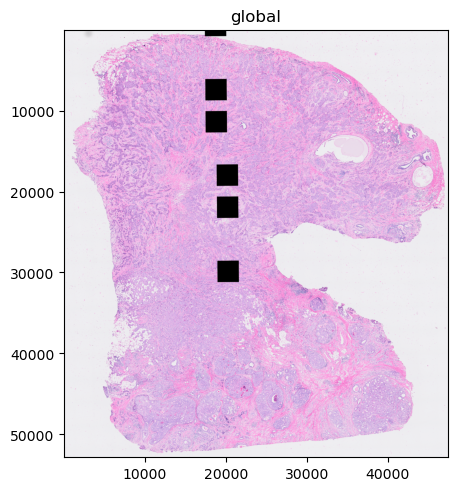

In [8]:
(
    sdata_crop.pl.render_images("hne_baked").pl.show()
)

We see that the image extends into negative coordinates. Let's crop it to the positive space

In [9]:

def _make_one_hex(args):
    i, j, x_hex_size, y_hex_size, x_min, y_min = args
    # Compute center offsets
    x_offset = x_min + i * 1.5 * x_hex_size
    y_offset = y_min + j * sqrt(3) * y_hex_size
    if i % 2 == 1:
        y_offset += (sqrt(3) / 2) * y_hex_size

    # Build flat-top hexagon vertices
    coords = [
        (x_offset,                           y_offset),
        (x_offset + x_hex_size / 2,         y_offset + sqrt(3) / 2 * y_hex_size),
        (x_offset + 1.5 * x_hex_size,       y_offset + sqrt(3) / 2 * y_hex_size),
        (x_offset + 2 * x_hex_size,         y_offset),
        (x_offset + 1.5 * x_hex_size,       y_offset - sqrt(3) / 2 * y_hex_size),
        (x_offset + x_hex_size / 2,         y_offset - sqrt(3) / 2 * y_hex_size),
        (x_offset,                           y_offset),
    ]
    return Polygon(coords)

def make_hexagonal_grid_parallel(
    x_min: float,
    x_max: float,
    y_min: float,
    y_max: float,
    desired_hex_width: float,
    n_workers: int = None
) -> GeoDataFrame:
    """
    Build a hexagonal grid in parallel, with tqdm progress bar.
    Cells are flat-topped; `desired_hex_width` is the horizontal
    diameter (flat-to-flat) of each hexagon in the same units
    as x_min/x_max (e.g., pixels).
    """

    # Derive side length from desired flat-to-flat width = 2 * side
    side = desired_hex_width / 2.0
    x_hex_size = side
    y_hex_size = side

    # Calculate how many cells we need to cover the extent
    n_cells_x = int(ceil((x_max - x_min) / (1.5 * side))) + 1
    n_cells_y = int(ceil((y_max - y_min) / (sqrt(3) * side))) + 1

    # Prepare tasks with x_min/y_min offsets included
    tasks = [
        (i, j, x_hex_size, y_hex_size, x_min, y_min)
        for i in range(n_cells_x)
        for j in range(n_cells_y)
    ]

    # Parallel map with progress bar
    geoms = []
    with ProcessPoolExecutor(max_workers=n_workers) as executor:
        for poly in tqdm(
            executor.map(_make_one_hex, tasks),
            total=len(tasks),
            desc="Building hexagons",
            unit="cell"
        ):
            geoms.append(poly)

    # Wrap into GeoDataFrame
    grid_gdf = GeoDataFrame({"geometry": geoms})
    return grid_gdf


In [10]:
_, y_max, x_max = sdata_crop["hne_baked"]["scale0"].image.shape
y_min = x_min = 0

desired_hex_width = 300.0  

hex_gdf = make_hexagonal_grid_parallel(
    x_min, x_max, y_min, y_max, desired_hex_width, n_workers=8
)

Building hexagons: 100%|██████████| 43460/43460 [00:06<00:00, 6355.12cell/s]


In [11]:
def hex_grid_to_mask(
    grid_gdf,
    image_shape: tuple[int,int],
    x_min: float = 0.0,
    y_min: float = 0.0
) -> np.ndarray:
    """
    Rasterize a GeoDataFrame of non-overlapping hexagon polygons
    into an integer mask of shape `image_shape` (H, W).  Each
    hexagon gets a unique label 1..N in index order; background=0.
    """

    H, W = image_shape

    # 1) Build an affine transform that maps pixel‐coordinates to
    #    the same units your polygons use.  Here we assume:
    #      +X = right, +Y = down, and units=pixels.
    #    So a pixel at row=i, col=j has world‐coords (x=j, y=i).
    transform = Affine.translation(x_min, y_min) * Affine.scale(1, 1)

    # 2) Prepare (geometry, value) tuples
    shapes = [
        (geom, idx+1)
        for idx, geom in enumerate(grid_gdf.geometry)
    ]

    # 3) Rasterize!
    mask = rasterize(
        shapes=shapes,
        out_shape=(H, W),
        transform=transform,
        fill=0,
        dtype=np.int32
    )

    return mask



In [12]:
H, W = y_max, x_max
mask = hex_grid_to_mask(hex_gdf, (H, W))

In [13]:
sdata_crop["hexes"] = Labels2DModel.parse(mask, scale_factors=[2, 2, 2, 2])

INFO     no axes information specified in the object, setting `dims` to: ('y', 'x')                                


In [14]:
sdata_crop

SpatialData object
├── Images
│     ├── 'hne': DataTree[cyx] (3, 41279, 37128), (3, 20640, 18565), (3, 10319, 9282), (3, 5160, 4641)
│     ├── 'hne_baked': DataTree[cyx] (3, 52833, 47441), (3, 26416, 23720), (3, 13207, 11860), (3, 6604, 5930)
│     ├── 'morphology_focus': DataTree[cyx] (1, 52833, 47441), (1, 26416, 23720), (1, 13208, 11860), (1, 6604, 5930), (1, 3302, 2965)
│     └── 'morphology_mip': DataTree[cyx] (1, 52833, 47441), (1, 26416, 23720), (1, 13208, 11860), (1, 6604, 5930), (1, 3302, 2965)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604, 5930), (3302, 2965)
│     ├── 'cell_labels_subset': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604, 5930), (3302, 2965)
│     ├── 'hexes': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604, 5930), (3302, 2965)
│     └── 'nucleus_labels': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604, 5930), (3302, 2965)
├── Points
│     └── 'tr

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


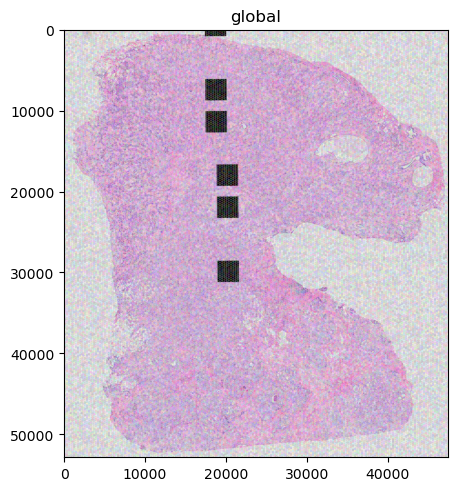

In [15]:
(
    sdata_crop
    .pl.render_images("hne_baked")
    .pl.render_labels("hexes", fill_alpha=0.1, outline_alpha=1)
    .pl.show()
)

In [17]:

def compute_hex_mean_dask(
    image_da: xr.DataArray,
    hex_mask: np.ndarray,
    channel: int,
    chunk_height: int = None,
) -> dict[int, float]:
    """
    Compute per-hex mean on a large Dask-backed xarray.DataArray by streaming stripes,
    with a tqdm progress bar. Only the specified RGB channel is used.
    
    Parameters
    ----------
    image_da : xr.DataArray
        Input image, shape (3, Y, X), with channels in dimension 'c'.
    hex_mask : np.ndarray
        Integer mask of shape (Y, X), where 0 = background and 1..N = hex IDs.
    channel : int
        Which color channel to use: 0=red, 1=green, 2=blue.
    chunk_height : int, optional
        Number of rows to process per stripe. Defaults to the first y-chunk of image_da.
    
    Returns
    -------
    mean_dict : dict[int, float]
        Mapping from each hex ID to its computed mean in the selected channel.
    """
    # Select only the requested channel
    img_chan = image_da.isel(c=channel)
    
    H, W = img_chan.sizes['y'], img_chan.sizes['x']
    # Determine stripe height
    if chunk_height is None and img_chan.chunks:
        y_axis = img_chan.get_axis_num('y')
        chunk_height = img_chan.chunks[y_axis][0]
    chunk_height = int(chunk_height or H)

    # Identify hex labels
    all_labels = np.unique(hex_mask)
    all_labels = all_labels[all_labels != 0]
    max_label = int(all_labels.max())

    # Allocate accumulators
    count  = np.zeros(max_label + 1, dtype=np.int64)
    sum_   = np.zeros(max_label + 1, dtype=np.float64)

    n_stripes = ceil(H / chunk_height)

    # Process stripes with progress bar
    for y0 in tqdm(range(0, H, chunk_height),
                   total=n_stripes,
                   desc="Hex mean stripes",
                   unit="stripe"):
        y1 = min(H, y0 + chunk_height)

        # Load image stripe
        stripe_da = img_chan.isel(y=slice(y0, y1))
        data = stripe_da.data
        if hasattr(data, 'compute'):
            stripe = data.compute()
        else:
            stripe = data
        stripe = np.asarray(stripe).astype(np.float64)

        # Load mask stripe and coerce to NumPy
        mask_stripe = np.asarray(hex_mask[y0:y1])

        # Check alignment
        if stripe.shape != mask_stripe.shape:
            raise ValueError(f"Shape mismatch: image {stripe.shape} vs mask {mask_stripe.shape}")

        # Flatten and accumulate counts and sums
        flat_vals = stripe.ravel()
        flat_mask = mask_stripe.ravel()
        bins = max_label + 1
        count += np.bincount(flat_mask, minlength=bins)
        sum_  += np.bincount(flat_mask, weights=flat_vals, minlength=bins)

    # Compute mean per label
    mean_vals = sum_ / count
    return {int(lbl): mean_vals[lbl] for lbl in all_labels}

def compute_hex_variance_dask(
    image_da: xr.DataArray,
    hex_mask: np.ndarray,
    channel: int,
    chunk_height: int = None,
) -> dict[int, float]:
    """
    Compute per-hex variance on a large Dask-backed xarray.DataArray by streaming stripes,
    with a tqdm progress bar. Only the specified RGB channel is used.
    
    Parameters
    ----------
    image_da : xr.DataArray
        Input image, shape (3, Y, X), with channels in dimension 'c'.
    hex_mask : np.ndarray
        Integer mask of shape (Y, X), where 0 = background and 1..N = hex IDs.
    channel : int
        Which color channel to use: 0=red, 1=green, 2=blue.
    chunk_height : int, optional
        Number of rows to process per stripe. Defaults to the first y-chunk of image_da.
    
    Returns
    -------
    var_dict : dict[int, float]
        Mapping from each hex ID to its computed variance in the selected channel.
    """
    # Select only the requested channel
    img_conv = image_da.isel(c=channel)
    
    H, W = img_conv.sizes['y'], img_conv.sizes['x']
    # Determine stripe height
    if chunk_height is None and img_conv.chunks:
        y_axis = img_conv.get_axis_num('y')
        chunk_height = img_conv.chunks[y_axis][0]
    chunk_height = int(chunk_height or H)

    # Identify hex labels
    all_labels = np.unique(hex_mask)
    all_labels = all_labels[all_labels != 0]
    max_label = int(all_labels.max())

    # Allocate accumulators
    count  = np.zeros(max_label + 1, dtype=np.int64)
    sum_   = np.zeros(max_label + 1, dtype=np.float64)
    sum_sq = np.zeros(max_label + 1, dtype=np.float64)

    n_stripes = ceil(H / chunk_height)

    # Process stripes with progress bar
    for y0 in tqdm(range(0, H, chunk_height),
                   total=n_stripes,
                   desc="Hex variance stripes",
                   unit="stripe"):
        y1 = min(H, y0 + chunk_height)
        # Load image stripe
        stripe_da = img_conv.isel(y=slice(y0, y1))
        data = stripe_da.data
        if hasattr(data, 'compute'):
            stripe = data.compute()
        else:
            stripe = data
        stripe = np.asarray(stripe).astype(np.float64)

        # Load mask stripe and coerce to NumPy
        mask_stripe = hex_mask[y0:y1]
        mask_stripe = np.asarray(mask_stripe)

        # Check alignment
        if stripe.shape != mask_stripe.shape:
            raise ValueError(f"Shape mismatch: image {stripe.shape} vs mask {mask_stripe.shape}")

        # Flatten and accumulate statistics
        flat_vals = stripe.ravel()
        flat_mask = mask_stripe.ravel()
        bins = max_label + 1
        count  += np.bincount(flat_mask, minlength=bins)
        sum_   += np.bincount(flat_mask, weights=flat_vals,      minlength=bins)
        sum_sq += np.bincount(flat_mask, weights=flat_vals**2,   minlength=bins)

    # Compute variance per label
    var = sum_sq / count - (sum_ / count)**2
    return {int(lbl): var[lbl] for lbl in all_labels}


def filter_hexes_by_variance(
    hex_mask,
    var_dict: dict[int, float],
    lower_threshold: float = None,
    upper_threshold: float = None
) -> np.ndarray:
    """
    Zero-out all hex IDs in `hex_mask` whose variance is outside the
    [lower_threshold, upper_threshold] range.

    Parameters
    ----------
    hex_mask : array-like (e.g., np.ndarray or xarray.DataArray)
        Integer mask of shape (H, W), where 0 = background and 1..N = hex IDs.
    var_dict : dict[int, float]
        Mapping from hex ID to its variance.
    lower_threshold : float, optional
        Any hex whose variance is strictly less than this will be set to 0.
        If None, no lower bound is applied.
    upper_threshold : float, optional
        Any hex whose variance is strictly greater than this will be set to 0.
        If None, no upper bound is applied.

    Returns
    -------
    new_mask : np.ndarray
        Copy of `hex_mask` with out-of-range hex IDs zeroed out.
    """
    # Coerce to NumPy array if necessary
    if hasattr(hex_mask, "values"):
        mask_arr = hex_mask.values
    else:
        mask_arr = np.asarray(hex_mask)

    new_mask = mask_arr.copy()

    # Determine which IDs to drop
    to_zero = []
    for hid, var in var_dict.items():
        if (lower_threshold is not None and var < lower_threshold) or \
           (upper_threshold is not None and var > upper_threshold):
            to_zero.append(hid)

    if to_zero:
        new_mask[np.isin(new_mask, to_zero)] = 0

    return new_mask

In [18]:
img = sdata_crop["hne_baked"]["scale0"].image
mask = sdata_crop["hexes"]["scale0"].image

In [19]:
mean_map = compute_hex_mean_dask(
    sdata_crop["hne_baked"]["scale0"].image,
    sdata_crop["hexes"]["scale0"].image,
    chunk_height=1024,
    channel=1
)

Hex mean stripes: 100%|██████████| 52/52 [00:53<00:00,  1.02s/stripe]
/tmp/ipykernel_1648814/1211615785.py:79: RuntimeWarning: invalid value encountered in divide
  mean_vals = sum_ / count


In [21]:
list(mean_map.values())[:5]

[238.10795376829435,
 238.32392367404165,
 236.37645771348448,
 238.65003771514776,
 238.93449714461582]

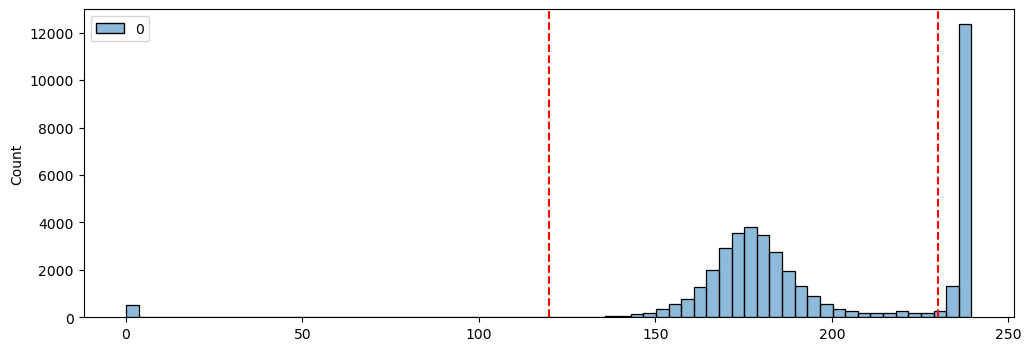

In [22]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(mean_map.values(), ax=ax)
ax.axvline(120, color="red", linestyle="--")
ax.axvline(230, color="red", linestyle="--")

In [23]:
filtered_hexes = filter_hexes_by_variance(mask, mean_map, 120, 230)

In [24]:
sdata_crop["filtered_hexes"] = Labels2DModel.parse(filtered_hexes, scale_factors=[2, 2, 2, 2])

INFO     no axes information specified in the object, setting `dims` to: ('y', 'x')                                


INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


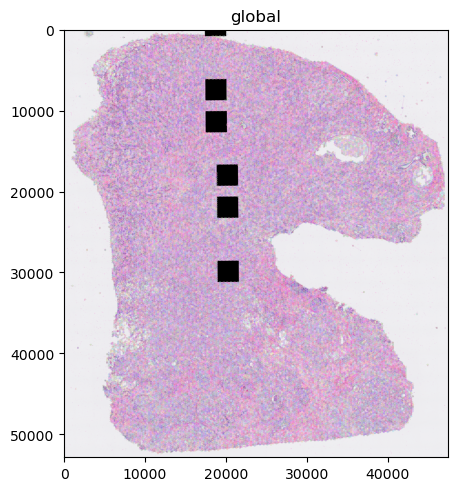

In [25]:
(
    sdata_crop
    .pl.render_images("hne_baked")
    .pl.render_labels("filtered_hexes", fill_alpha=0.1, outline_alpha=1)
    .pl.show()
)

In [26]:
sdata_crop

SpatialData object
├── Images
│     ├── 'hne': DataTree[cyx] (3, 41279, 37128), (3, 20640, 18565), (3, 10319, 9282), (3, 5160, 4641)
│     ├── 'hne_baked': DataTree[cyx] (3, 52833, 47441), (3, 26416, 23720), (3, 13207, 11860), (3, 6604, 5930)
│     ├── 'morphology_focus': DataTree[cyx] (1, 52833, 47441), (1, 26416, 23720), (1, 13208, 11860), (1, 6604, 5930), (1, 3302, 2965)
│     └── 'morphology_mip': DataTree[cyx] (1, 52833, 47441), (1, 26416, 23720), (1, 13208, 11860), (1, 6604, 5930), (1, 3302, 2965)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604, 5930), (3302, 2965)
│     ├── 'cell_labels_subset': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604, 5930), (3302, 2965)
│     ├── 'filtered_hexes': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604, 5930), (3302, 2965)
│     ├── 'hexes': DataTree[yx] (52833, 47441), (26416, 23720), (13208, 11860), (6604, 5930), (3302, 2965)
│     └── 'nucleus_label

In [27]:
del sdata_crop["hne"]
del sdata_crop["hexes"]
del sdata_crop["morphology_focus"]
del sdata_crop["morphology_mip"]
del sdata_crop["cell_labels_subset"]
del sdata_crop["nucleus_labels"]
del sdata_crop["transcripts"]
del sdata_crop["cell_boundaries"]
del sdata_crop["cell_circles"]
del sdata_crop["nucleus_boundaries"]
del sdata_crop["table_subset"]

In [47]:
sdata_crop.write(data_dir / "xenium_sample1_hexes300.zarr", overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside                                                                                         
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_hexes3000.zarr). Please see   
         the documentation of `is_self_contained()` to understand the implications of working with SpatialData     
         objects that are not self-contained.                                                                      
INFO     The Zarr backing store has been changed from                                                              
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_hexes300.zarr the new file    
         path: /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_hexes3000.zarr          


## Sample 2

In [48]:
sdata_sample2 = sd.read_zarr(data_dir / "xenium_sample2_subset_baked_cropped.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


In [49]:
sdata_sample2

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2_subset_baked_cropped.zarr
├── Images
│     ├── 'hne_baked': DataTree[cyx] (3, 41411, 45749), (3, 20705, 22874), (3, 10352, 11437), (3, 5175, 5718)
│     ├── 'morphology_focus': DataTree[cyx] (1, 41411, 45749), (1, 20705, 22874), (1, 10352, 11437), (1, 5176, 5718), (1, 2588, 2859)
│     └── 'morphology_mip': DataTree[cyx] (1, 41411, 45749), (1, 20705, 22874), (1, 10352, 11437), (1, 5176, 5718), (1, 2588, 2859)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
│     ├── 'cell_labels_subset': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
│     └── 'nucleus_labels': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 8) (3D points)
├── Shapes
│    

INFO     Rasterizing image for faster rendering.                                                                   


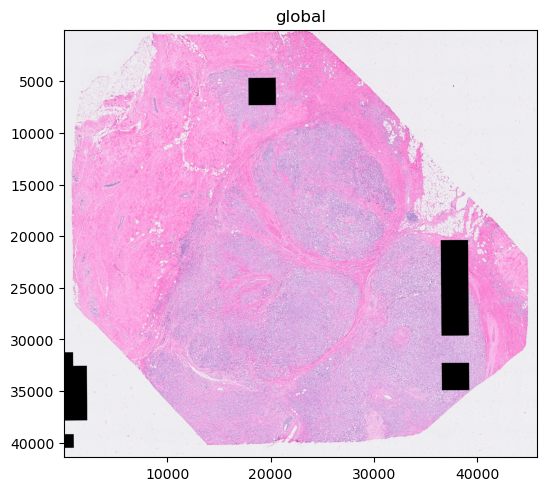

In [50]:
(
    sdata_sample2.pl.render_images("hne_baked").pl.show()
)

In [51]:

# Example usage:
_, y_max, x_max = sdata_sample2["hne_baked"]["scale0"].image.shape
y_min = x_min = 0

desired_hex_width = 300.0  

hex_gdf = make_hexagonal_grid_parallel(
    x_min, x_max, y_min, y_max, desired_hex_width, n_workers=8
)

H, W = y_max, x_max
mask = hex_grid_to_mask(hex_gdf, (H, W))


Building hexagons: 100%|██████████| 33005/33005 [00:05<00:00, 6046.91cell/s]


In [52]:
img = sdata_sample2["hne_baked"]["scale0"].image

In [53]:
mean_map = compute_hex_mean_dask(img, mask, chunk_height=1024, channel=1)

Hex mean stripes: 100%|██████████| 41/41 [00:25<00:00,  1.62stripe/s]
/tmp/ipykernel_1648814/1211615785.py:79: RuntimeWarning: invalid value encountered in divide
  mean_vals = sum_ / count


In [54]:
list(mean_map.values())[:5]

[237.3719737382027,
 237.8814417125466,
 237.76023391812865,
 236.9721593636426,
 237.78505967240022]

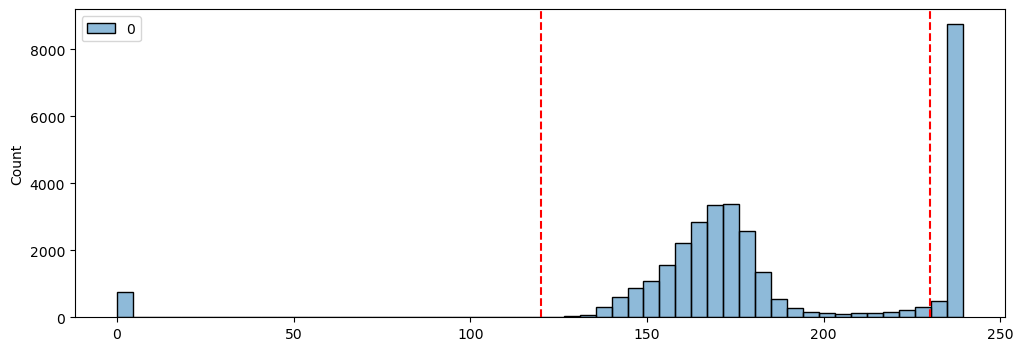

In [55]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(mean_map.values(), ax=ax)
ax.axvline(120, color="red", linestyle="--")
ax.axvline(230, color="red", linestyle="--")

In [56]:
filtered_hexes = filter_hexes_by_variance(mask, mean_map, 120, 230)

In [57]:
sdata_sample2["filtered_hexes"] = Labels2DModel.parse(filtered_hexes, scale_factors=[2, 2, 2, 2])

INFO     no axes information specified in the object, setting `dims` to: ('y', 'x')                                


INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


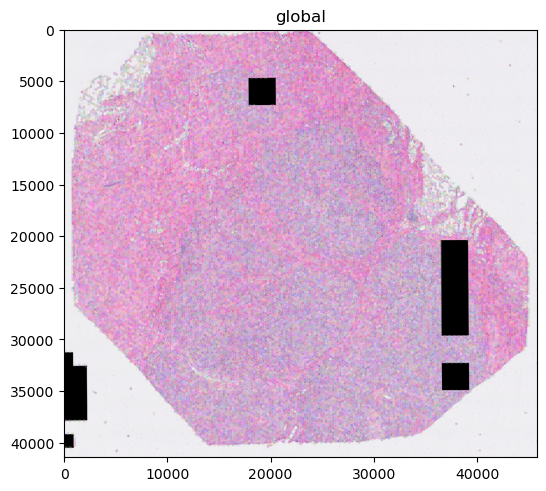

In [58]:
(
    sdata_sample2
    .pl.render_images("hne_baked")
    .pl.render_labels("filtered_hexes", fill_alpha=0.1, outline_alpha=1)
    .pl.show()
)

In [59]:
sdata_sample2

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2_subset_baked_cropped.zarr
├── Images
│     ├── 'hne_baked': DataTree[cyx] (3, 41411, 45749), (3, 20705, 22874), (3, 10352, 11437), (3, 5175, 5718)
│     ├── 'morphology_focus': DataTree[cyx] (1, 41411, 45749), (1, 20705, 22874), (1, 10352, 11437), (1, 5176, 5718), (1, 2588, 2859)
│     └── 'morphology_mip': DataTree[cyx] (1, 41411, 45749), (1, 20705, 22874), (1, 10352, 11437), (1, 5176, 5718), (1, 2588, 2859)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
│     ├── 'cell_labels_subset': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
│     ├── 'filtered_hexes': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
│     └── 'nucleus_labels': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718)

In [60]:
del sdata_sample2["morphology_focus"]
del sdata_sample2["morphology_mip"]
del sdata_sample2["cell_labels_subset"]
del sdata_sample2["nucleus_labels"]
del sdata_sample2["transcripts"]
del sdata_sample2["cell_boundaries"]
del sdata_sample2["cell_circles"]
del sdata_sample2["nucleus_boundaries"]
del sdata_sample2["table_subset"]

In [61]:
sdata_sample2

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2_subset_baked_cropped.zarr
├── Images
│     └── 'hne_baked': DataTree[cyx] (3, 41411, 45749), (3, 20705, 22874), (3, 10352, 11437), (3, 5175, 5718)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
│     └── 'filtered_hexes': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
└── Tables
      └── 'table': AnnData (365604, 380)
with coordinate systems:
    ▸ 'global', with elements:
        hne_baked (Images), cell_labels (Labels), filtered_hexes (Labels)
with the following elements not in the Zarr store:
    ▸ filtered_hexes (Labels)
with the following elements in the Zarr store but not in the SpatialData object:
    ▸ morphology_focus (Images)
    ▸ cell_labels_subset (Labels)
    ▸ cell_boundaries (Shapes)
    ▸ nucleus_labels (Labels)
    ▸ transcript

In [62]:
sdata_sample2.write(data_dir / "xenium_sample2_hexes300.zarr", overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside                                                                                         
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2_hexes300.zarr). Please see the
         documentation of `is_self_contained()` to understand the implications of working with SpatialData objects 
         that are not self-contained.                                                                              
INFO     The Zarr backing store has been changed from                                                              
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2_subset_baked_cropped.zarr the 
         new file path: /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2_hexes300.zarr  
